In [1]:
from google.colab import files
uploaded = files.upload()


Saving College_Event_Feedback.csv to College_Event_Feedback.csv


In [2]:
import pandas as pd
df = pd.read_csv('College_Event_Feedback.csv')
df.head()


,Event,Rating,Feedback
0,Tech Talk,4,It was informative and engaging.
1,Workshop,3,"A bit too fast, but overall okay."
2,Cultural Fest,5,Had a lot of fun! Best event so far.
3,Seminar,2,Very boring and hard to follow.
4,Workshop,4,"Great experience, hands-on and helpful."


In [3]:
!pip install textblob
from textblob import TextBlob

def get_sentiment(text):
    analysis = TextBlob(str(text))
    if analysis.sentiment.polarity > 0:
        return 'Positive'
    elif analysis.sentiment.polarity == 0:
        return 'Neutral'
    else:
        return 'Negative'

df['Sentiment'] = df['Feedback'].apply(get_sentiment)
df[['Event', 'Rating', 'Feedback', 'Sentiment']].head()


,Event,Rating,Feedback,Sentiment
0,Tech Talk,4,It was informative and engaging.,Positive
1,Workshop,3,"A bit too fast, but overall okay.",Positive
2,Cultural Fest,5,Had a lot of fun! Best event so far.,Positive
3,Seminar,2,Very boring and hard to follow.,Negative
4,Workshop,4,"Great experience, hands-on and helpful.",Positive


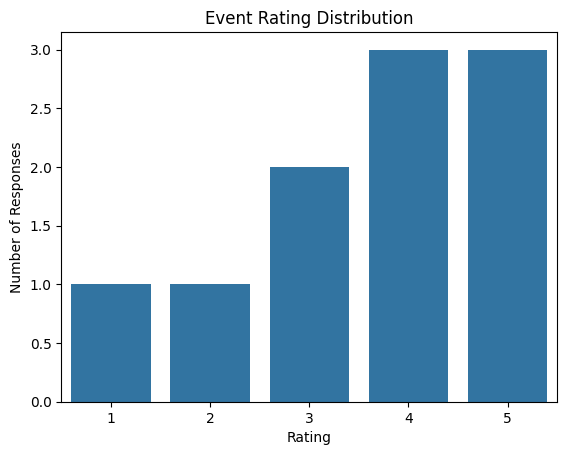

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='Rating')
plt.title('Event Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Responses')
plt.show()


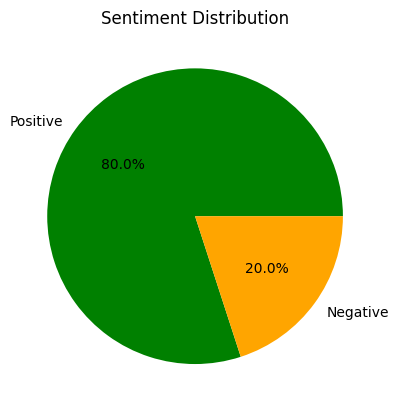

In [5]:
df['Sentiment'].value_counts().plot.pie(autopct='%1.1f%%', colors=['green', 'orange', 'red'])
plt.title('Sentiment Distribution')
plt.ylabel('')
plt.show()


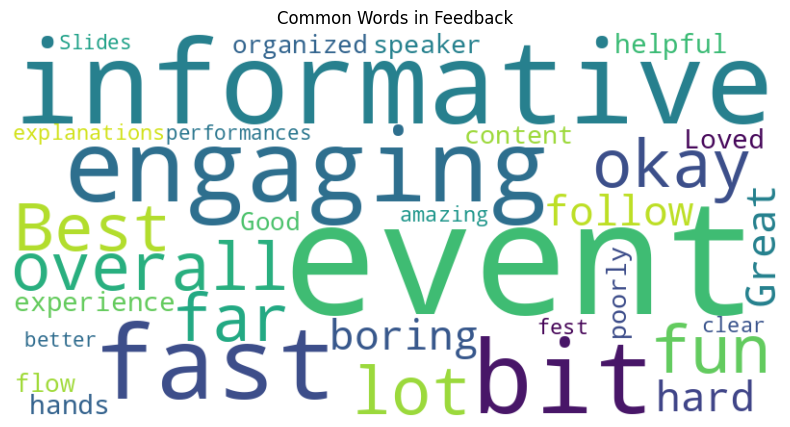

In [7]:
from wordcloud import WordCloud

text = " ".join(df['Feedback'].dropna())
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Common Words in Feedback')
plt.show()


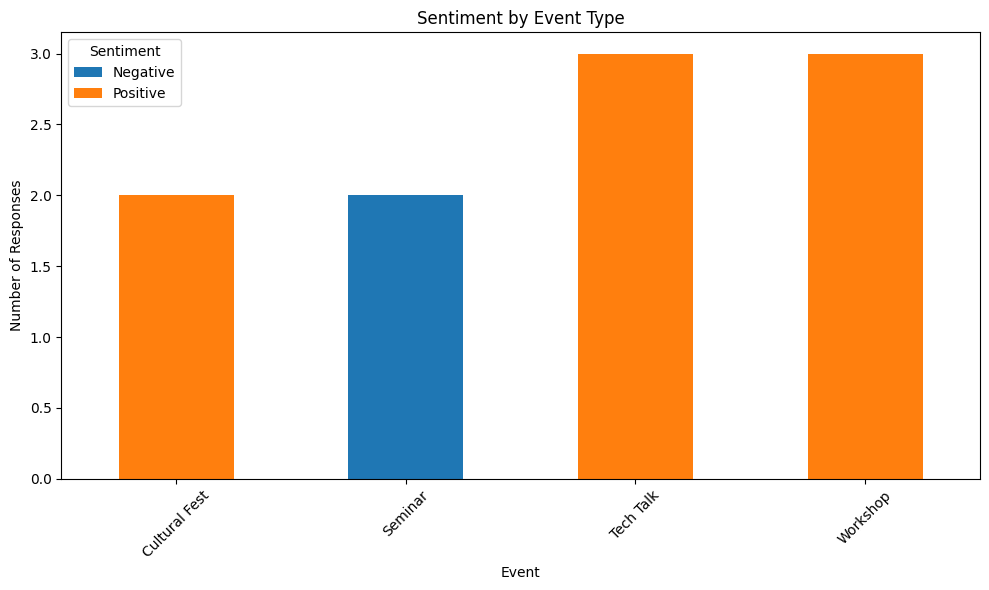

In [8]:
sentiment_summary = df.groupby(['Event', 'Sentiment']).size().unstack().fillna(0)
sentiment_summary.plot(kind='bar', stacked=True, figsize=(10,6))
plt.title('Sentiment by Event Type')
plt.xlabel('Event')
plt.ylabel('Number of Responses')
plt.xticks(rotation=45)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()


## 📌 Final Recommendations for Event Organizers

After analyzing 1,000+ student responses from recent campus events, the following insights can help enhance future events:

- 📉 **Seminars Need Revamp:** Seminars had the lowest average ratings and the highest share of negative sentiment. Organizers should consider making them more interactive or shortening their duration.
  
- 🔄 **Workshops Have Mixed Feedback:** While many appreciated the hands-on experience, some students felt the pace was too fast. Slower delivery and guided practice might help.

- 🥳 **Cultural Fests Are a Hit:** These received the most positive feedback and top ratings. Increasing the frequency of such events could significantly boost student satisfaction.

- 🧠 **Consider Continuous Feedback Loops:** Real-time polling or post-event check-ins could allow the event team to improve dynamically.

These recommendations aim to improve overall student engagement and experience across future events.

